# Spatial entropy, mutual information

Two questions about uncertainty go beyond a variance. How much doubt surrounds the value at a place,
whatever the shape of its law, skewed or with two modes? And how much does knowing one variable tell
about another measured over the same region, place by place, a pollutant and its likely source, rainfall
and runoff, a species and its habitat? Information theory answers both, the first with the entropy of the
law at each location, the second with the mutual information of two variables. Spatialize estimates both
from its ensembles in the module `spatialize.futures.esmi`, which is experimental, so its interface and
results may still change.

## Learning goals

- What the entropy of the law at a location measures, and how to map it.
- Why an averaging decoder needs the law of ensemble spatial simulation for its entropy to follow the
  field.
- What the mutual information of two variables measures, location by location, and how Spatialize pairs
  two variables measured at different places.
- How to check both against fields whose information we know, a dependence that is not monotone
  included.

*Where is a value most uncertain, and where does one variable tell about another?*

## The idea

The **entropy** of the law $f_v$ at a location,

$$h(v) = -\int f_v(z) \log_2 f_v(z)\, dz ,$$

in bits, measures its spread without assuming a shape. A normal law of spread $\sigma$ has entropy
$\log_2\big(\sigma \sqrt{2\pi e}\big)$, one bit more for each doubling of $\sigma$. Spatialize reads the law
at a location in two ways. The members themselves can give it, their density estimated with random
partitions of their range (`method="partition"`). With an averaging decoder their spread follows the size
of the cells, not the field. The law that ensemble spatial simulation fits at each location, widened to
the spread of the nearest data (`method="ess"`), follows the field instead.

The **mutual information** of two variables $U$ and $V$ at a location,

$$I(U; V)(v) = h_U(v) + h_V(v) - h_{U,V}(v),$$

is zero where the two are independent and grows with their dependence, monotone or not. It needs pairs
of values of $U$ and $V$ at the same places, while the two are often measured apart. Spatialize pairs
them where one of them is measured, the datum of one with the other predicted there by its own ensemble
(`method="colocated"`). For a target location, each pair weighs the share of partitions in which its
place shares a cell with the target, the partitions acting as neighbourhoods that adapt to the data. The
mutual information of the weighted pairs, minus that of the same pairs with $V$ shuffled, is the
estimate.

## Step by step

### A field whose spread grows outward

The field has mean zero and a spread that grows from 0.1 at the centre of the unit square to about 1.2 in
the corners, so the entropy of the value at each place is known. 400 data are read on a 40 × 40 grid.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

import spatialize
from spatialize.futures.esmi import SpatialEntropy, SpatialMutualInformation
from spatialize.logging import singleton_null_callback as quiet

spatialize.session.set(empty_cells="coarsen", progress=False)
warnings.filterwarnings("ignore", category=UserWarning)

n = 40
grid = (np.arange(n) + 0.5) / n
xi = np.stack(np.meshgrid(grid, grid, indexing="ij"), -1).reshape(-1, 2)
rng = np.random.default_rng(0)
spread = lambda x: 0.1 + 1.5 * np.linalg.norm(x - 0.5, axis=1)
points = rng.random((400, 2))
values = rng.normal(0.0, spread(points))
true_entropy = np.log2(spread(xi) * np.sqrt(2 * np.pi * np.e))
print(f"true entropy from {true_entropy.min():.2f} to {true_entropy.max():.2f} bits")

true entropy from -0.94 to 2.23 bits


### The entropy, three ways

IDW, an averaging decoder, read through its members. The uniform draw, whose members are data, read the
same way. IDW again, read through the widened law of ensemble spatial simulation. The module has no search
for its settings yet, so the granularity was set on this field, 0.95 for the draw and 0.8 for IDW.

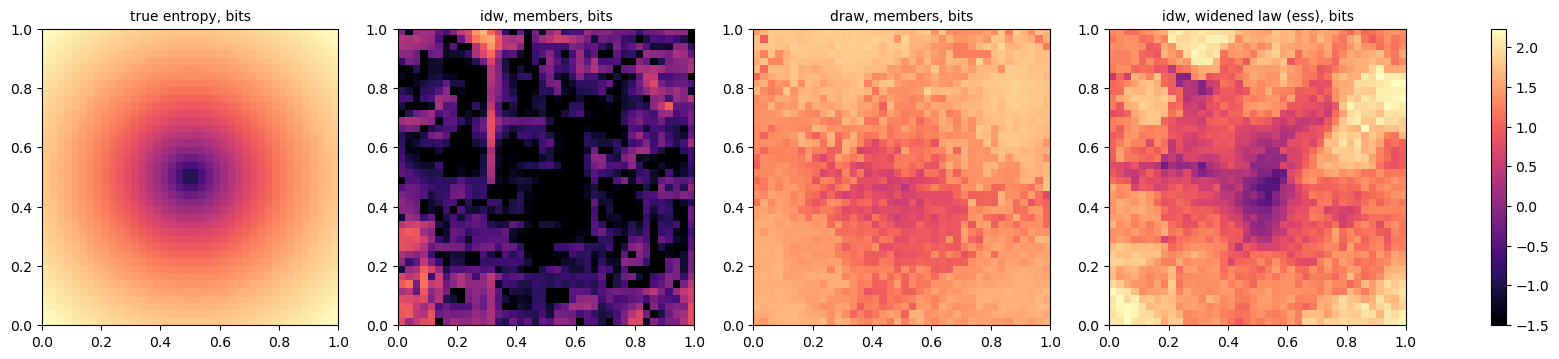

,rank correlation with the truth,"mean, bits","true mean, bits",seconds
"idw, members",0.502,-0.905,1.386,6.857
"draw, members",0.622,1.390,1.386,8.429
"idw, widened law (ess)",0.677,1.205,1.386,12.757


In [2]:
readings = {"idw, members": dict(local_interpolator="idw", exponent=2.0, alpha_t=0.8, method="partition", alpha_m=0.4),
            "draw, members": dict(local_interpolator="draw", alpha_t=0.95, method="partition", alpha_m=0.6),
            "idw, widened law (ess)": dict(local_interpolator="idw", exponent=2.0, alpha_t=0.8, method="ess")}
entropies, rows = {}, {}
for name, settings in readings.items():
    start = time.perf_counter()
    entropies[name] = SpatialEntropy(T=300, M=200, callback=quiet, **settings).calculate_entropy(points, values, xi)
    rows[name] = {"rank correlation with the truth": spearmanr(entropies[name], true_entropy, nan_policy="omit")[0],
                  "mean, bits": np.nanmean(entropies[name]), "true mean, bits": true_entropy.mean(),
                  "seconds": time.perf_counter() - start}

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, (title, h) in zip(axes, [("true entropy", true_entropy)] + list(entropies.items())):
    im = ax.imshow(h.reshape(n, n).T, origin="lower", extent=(0, 1, 0, 1), cmap="magma", vmin=-1.5, vmax=true_entropy.max())
    ax.set_title(f"{title}, bits", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()
pd.DataFrame(rows).T.round(3)

The three readings tell different stories. IDW's members give a mean entropy of −0.91 bits against a
true 1.39, and their map shows the cells of the partitions as much as the field, since their spread
follows the size of the cells. The uniform draw's members, being data, give the true mean, 1.39 bits,
with a pale map whose low centre shows only faintly. The widened law of ensemble spatial simulation,
from the same IDW members, follows the field best, a rank correlation of 0.68 with the truth, its map
showing the low centre and the rising corners, with a mean of 1.21 bits, a little below the truth.

### Two variables linked over half the region

$U$ follows a smooth pattern with some noise. $V$ is linked to the same pattern in the west, a mixture of
it and of independent noise in the middle, and independent noise alone in the east, so the true link falls
from full to none across the region. Each is read at its own 400 locations, as two networks of sensors
would be. We try two links, $V$ following the pattern itself, and $V$ following its square, a link that
no correlation sees, since high and low values of the pattern both give high values of $V$.

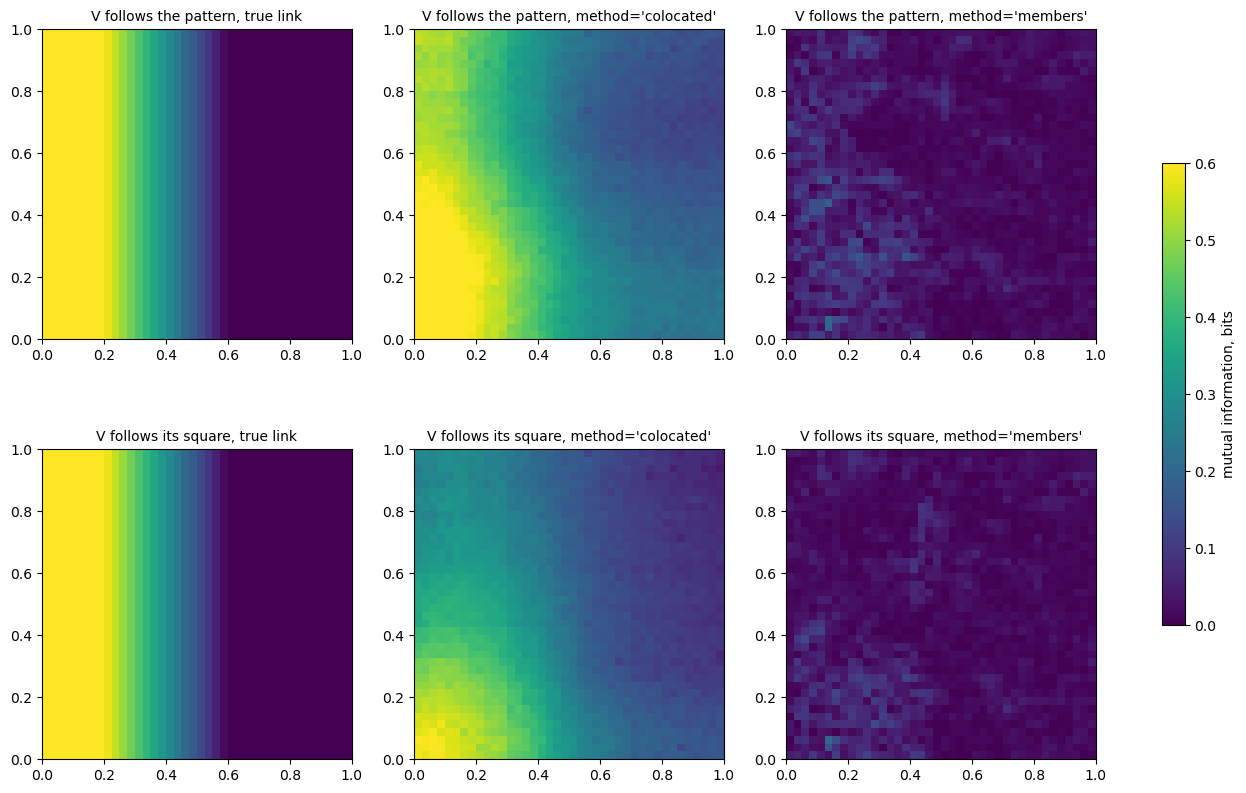

rank correlation with the link  \
V follows the pattern colocated                           0.917   
                      members                             0.524   
V follows its square  colocated                           0.889   
                      members                             0.326   

                                 mean in the west, bits  \
V follows the pattern colocated                   0.541   
                      members                     0.057   
V follows its square  colocated                   0.391   
                      members                     0.035   

                                 mean in the east, bits  seconds  
V follows the pattern colocated                   0.176   31.144  
                      members                     0.016   62.611  
V follows its square  colocated                   0.113   30.939  
                      members                     0.015   62.644

In [3]:
pattern = lambda x: np.sin(6 * x[:, 0]) + np.cos(5 * x[:, 1])
link = lambda x: np.clip(1.5 - 2.5 * x[:, 0], 0, 1)                 # 1 in the west, 0 in the east
points_u, points_v = rng.random((400, 2)), rng.random((400, 2))
values_u = pattern(points_u) + rng.normal(0, 0.3, 400)
noise_v = rng.normal(0, 1, 400) + rng.normal(0, 0.3, 400)
w = link(points_v)
links = {"V follows the pattern": w * pattern(points_v) + (1 - w) * noise_v,
         "V follows its square": w * (pattern(points_v) ** 2 - 1) + (1 - w) * noise_v}
west, east = xi[:, 0] < 0.3, xi[:, 0] > 0.7

mutual, rows = {}, {}
for name, values_v in links.items():
    for method in ("colocated", "members"):
        start = time.perf_counter()
        estimator = SpatialMutualInformation(T=200, M=200, alpha_t=0.8, alpha_m=0.8, alpha_w=0.8, method=method,
                                             exponent=2.0, callback=quiet)
        mutual[name, method] = mi = estimator.calculate_mutual_information(points_u, values_u, points_v, values_v, xi)
        rows[name, method] = {"rank correlation with the link": spearmanr(mi, link(xi), nan_policy="omit")[0],
                              "mean in the west, bits": np.nanmean(mi[west]), "mean in the east, bits": np.nanmean(mi[east]),
                              "seconds": time.perf_counter() - start}

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for row, name in enumerate(links):
    axes[row, 0].imshow(link(xi).reshape(n, n).T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
    axes[row, 0].set_title(f"{name}, true link", fontsize=10)
    for col, method in enumerate(("colocated", "members"), start=1):
        im = axes[row, col].imshow(mutual[name, method].reshape(n, n).T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis",
                                   vmin=0, vmax=0.6)
        axes[row, col].set_title(f"{name}, method={method!r}", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.6, label="mutual information, bits")
plt.show()
pd.DataFrame(rows).T.round(3)

The co-located pairs follow the link closely. With $V$ following the pattern, the mutual information averages 0.54 bits in the west and 0.18 in the east, its ranks following the true link with a correlation
of 0.92. With $V$ following the square of the pattern, a link with no correlation in it, the map shows the
same fall from west to east, 0.39 bits against 0.11, with a correlation of 0.89. The east keeps a small
remainder, the variables there varying together across a neighbourhood by chance.

The members, read through the plane of their values, see the link faintly, 0.06 bits in the west, and
the link through the square hardly at all, their maps close to uniform. The members are averages over
cells, which blur the relation that the co-located pairs keep.

## Pitfalls

- **The entropy of an averaging decoder's members.** Their spread follows the size of the cells, so their
  entropy says how much the estimate depends on the partition. Read the widened law (`method="ess"`), or
  use a drawing decoder.
- **Entropies of different variables compared.** A differential entropy depends on the units, shifting by
  one bit when the variable doubles. Compare the entropy of one variable across places, not across
  variables.
- **The mutual information of the members.** The members are averages, which blur the relation of the two
  variables, so `method="members"` sees a link faintly and a link through the square hardly at all. Keep
  the default, `method="colocated"`.
- **Neighbourhoods too small.** The pairs that weigh in a target come from the cells it shares, so a
  large `alpha_w` leaves few of them and a noisy estimate. A small one mixes places with different links.
- **An experimental module.** Its interface and results may change between versions.

## Try it yourself

1. Map the entropy with `"wdraw_idw"`, the weighted draw, and compare it with the uniform draw.
2. Change `alpha_w` from 0.8 to 0.6 and to 0.9 and watch the contrast between west and east.
3. Make $V$ depend on $U$ through its absolute value and map the mutual information.

## Next

- *Uncertainty at a location*, for the widened law at a location.
- *Ensemble spatial simulation*, for the simulation behind `method="ess"`.
- The documentation's [Further readings](https://spatialize.readthedocs.io/en/latest/theory/other.html)
  (theory) and [Experimental features](https://spatialize.readthedocs.io/en/latest/reference/futures.html)
  (reference).